# Touches and possession: what the ball track can and cannot carry

Splits the ball track at touches (sudden velocity changes), attributes each touch to a team,
and decides possession with a **control rule** on top of the touch list: possession changes
only when the new team shows control, and the change goes at its *first* touch. The naive
"one touch = possession" rule runs alongside for comparison. Scripts: `touches.py`
(competition match) and `validate_metrica.py` (Metrica Sample Game 3, open data with events).
Definitions, defaults and where they depart from the plan: `README.md` in this folder.

> **Run this notebook on the VM only.** Once run, its outputs are aggregates of the competition
> match. Before a copy with outputs leaves the VM, clear it:
> `jupyter nbconvert --clear-output --inplace touch_possession.ipynb`.

The script commands are comments: run them in a VM terminal from the team-repo root. The cells
below them read only the two summary CSVs under `EDA_OUT` (default `~/eda_out`); no cell reads
match data or the frame-indexed `touches.csv` / `touch_labels.csv`. Charts use the shared look
from `../notebooks/plot_helpers.py`: dark ink for observed values, a light grey band (p5-p95)
with a dashed mean for the circular-shift null.

In [1]:
import os
import sys
from pathlib import Path

# This folder (Jupyter's working directory when the notebook is opened from it) and the script
# outputs. Override with TOUCH_DIR / EDA_OUT in the shell that starts Jupyter.
TOUCH_DIR = Path(os.environ.get("TOUCH_DIR", Path.cwd()))
EDA_OUT = Path(os.environ.get("EDA_OUT", Path.home() / "eda_out"))
sys.path.insert(0, str(TOUCH_DIR.parent / "notebooks"))

print("touch_possession folder:", TOUCH_DIR,
      "(plot_helpers found)" if (TOUCH_DIR.parent / "notebooks" / "plot_helpers.py").is_file()
      else "(plot_helpers.py MISSING: set TOUCH_DIR)")
print("EDA_OUT                :", EDA_OUT)

touch_possession folder: /home/amyln/mtah/more-than-a-hack/eda/touch_possession (plot_helpers found)
EDA_OUT                : /home/amyln/eda_out


In [2]:
%matplotlib inline
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import plot_helpers as ph

ph.style()
pd.set_option("display.width", 140)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # categorical slots 1-3 (fixed order)
FPS = 25

tp = ph.load_summary(EDA_OUT, "touch_possession", "touch_possession_summary.csv")
val = ph.load_summary(EDA_OUT, "touch_validation", "touch_validation_summary.csv")


def g(df, analysis, scope, bin_, metric):
    return ph.get(df, analysis, scope, bin_, metric)


def pct(x, nd=0):
    return "-" if x is None or not np.isfinite(x) else "{:.{}f}%".format(100 * x, nd)


def num(x, fmt="{:.2f}"):
    return "-" if x is None or not np.isfinite(x) else fmt.format(x)


graded_min = g(tp, "funnel", "all", "", "graded_frames") / FPS / 60
visible_min = g(tp, "funnel", "all", "", "visible_frames") / FPS / 60
print("BAR-ATH: {:.0f} graded minutes, ball visible on {:.0f} of them ({:.0%})".format(
    graded_min, visible_min, visible_min / graded_min))
print("team 0 = H = {}, team 1 = A = {}".format(ph.get(tp, "params", "team 0", "", "name", text=True),
                                              ph.get(tp, "params", "team 1", "", "name", text=True)))
print("touch window w = {:g} frames each side, touch threshold {:g} m/s, attribution limit {:g} m"
      .format(g(tp, "params", "all", "", "dv_half"), g(tp, "params", "all", "", "min_dv_ms"),
              g(tp, "params", "all", "", "max_dist_m")))

BAR-ATH: 106 graded minutes, ball visible on 63 of them (59%)
team 0 = H = Barcelona, team 1 = A = Atletic Club
touch window w = 12 frames each side, touch threshold 3 m/s, attribution limit 2 m


## 1. How sharp is a touch in this ball track?

The plan detects touches with mean velocities over 3-5 frames each side. That only works if a
kick shows up as a sudden change in the track. The test: count velocity-change peaks per minute
of visible ball at growing window half-widths `w`. On a raw track the count is flat in `w`. On a
low-pass filtered track it grows until `w` spans the filter.

In [3]:
# cd ~/more-than-a-hack
# PYTHONPATH="$PWD" python3 eda/touch_possession/touches.py "$HOME/eda_out/touch_possession"
# python3 eda/touch_possession/validate_metrica.py "$HOME/eda_out/touch_validation" \
#     --raw .../Sample_Game_3_tracking.txt --meta .../Sample_Game_3_metadata.xml \
#     --events .../Sample_Game_3_events.json --jump-touch

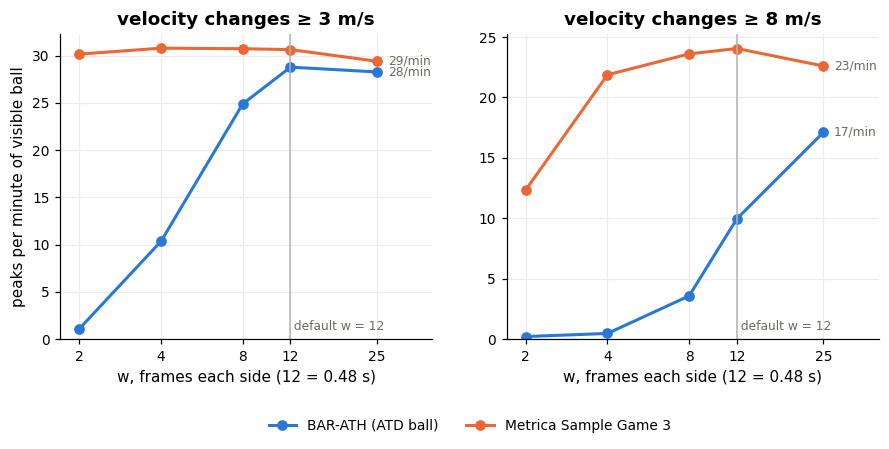

,BAR-ATH (ATD ball),Metrica Sample Game 3
"peaks/min, dv ≥ 3 m/s",,
w = 2,1.1,30.2
w = 4,10.4,30.8
w = 8,24.9,30.7
w = 12,28.8,30.6
w = 25,28.3,29.4


In [4]:
W = [2, 4, 8, 12, 25]
SERIES = [(tp, "BAR-ATH (ATD ball)", BLUE), (val, "Metrica Sample Game 3", ORANGE)]
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
for ax, dv in zip(axes, (3, 8)):
    for df, name, col in SERIES:
        y = [g(df, "timescale", "w={}".format(w), "dv>={}".format(dv), "peaks_per_visible_min")
             for w in W]
        ax.plot(W, y, color=col, lw=2, marker="o", ms=6, label=name)
        ax.annotate("{:.0f}/min".format(y[-1]), (W[-1], y[-1]), xytext=(7, 0),
                    textcoords="offset points", va="center", fontsize=8, color=ph.INK_2)
    ax.axvline(12, color=ph.INK_3, lw=1)
    ax.text(12, 0.03, " default w = 12", fontsize=8, color=ph.INK_2,
            transform=ax.get_xaxis_transform())
    ax.set_xscale("log")
    ax.set_xticks(W, [str(w) for w in W])
    ax.minorticks_off()
    ax.set_xlim(1.7, 40)
    ax.set_ylim(0, None)
    ax.set_xlabel("w, frames each side (12 = 0.48 s)")
    ax.set_title("velocity changes ≥ {} m/s".format(dv))
axes[0].set_ylabel("peaks per minute of visible ball")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.1, -0.22), ncol=2)
plt.show()

display(pd.DataFrame({name: ["{:.1f}".format(g(df, "timescale", "w={}".format(w), "dv>=3",
                                                  "peaks_per_visible_min")) for w in W]
                      for df, name, _ in SERIES}, index=["w = {}".format(w) for w in W])
        .rename_axis("peaks/min, dv ≥ 3 m/s"))

**How to read this.** Each line is the number of velocity-change peaks per minute of visible
ball as the averaging window widens. Sample Game 3 (orange) is flat from the smallest window: a
pass is a corner in its track. The competition ball (blue) has almost no sharp changes at
w = 2-4 and keeps gaining peaks until about w = 12.

**Takeaway.** The ATD ball is already smoothed by the provider. A kick is spread over about
half a second, so at the plan's 3-5 frame window it shows about 10 velocity changes per minute
of visible ball, where Sample Game 3 has about 30. The detector therefore uses w = 12. That number comes from this unlabelled
curve, not from the ground truth. The price is timing: a touch is now located only to within a
few frames of the true kick, and if the provider's filter is causal its peak could even lag the
kick. The public-window convention check (`--gt`) is the place to see that, without tuning on it.

## 2. Does the detector find real touches? (Sample Game 3, against its events)

Reference touches are the event data's pass starts and receptions, shots, recoveries and balls
lost. A detected touch matches a reference touch within ±0.4 s, one to one. `full` is the ball
as given. The two `deleted` conditions delete the ball in bursts, mostly long ones as on our
match, until 41% of graded frames are missing; `deleted_crowd` deletes more often where players
crowd the ball. Attribution limit 2 m throughout.

*Caveat:* this ball is rebuilt from event positions (median 0.06 m from the toucher), so these
are upper bounds for real tracking.

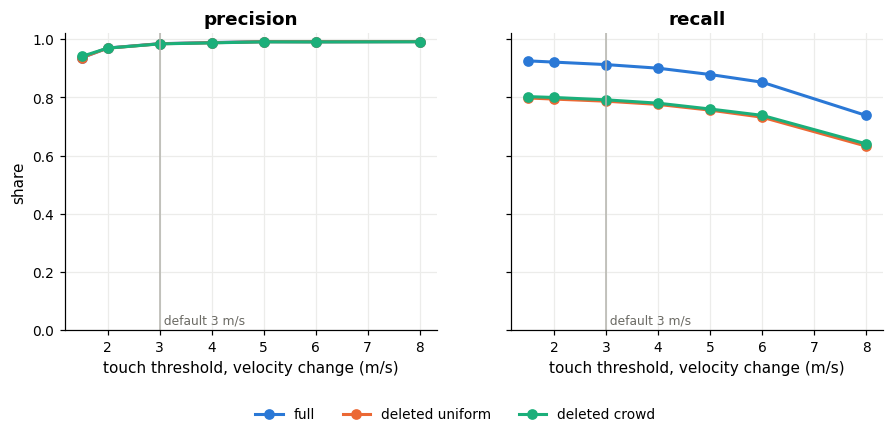

,full,deleted uniform,deleted crowd
"at dv ≥ 3 m/s, ≤ 2 m",,,
ball missing,32%,41%,41%
precision,98%,98%,98%
recall,91%,79%,79%
recall where the ball is visible,91%,90%,91%
team right (uncontested),99.5%,99.4%,99.4%
contested,6%,7%,7%
offset median (s),0.00,0.00,0.00
recall: recoveries,89%,80%,77%
recall: receptions,96%,82%,83%


In [5]:
CONDS = [("full", BLUE), ("deleted_uniform", ORANGE), ("deleted_crowd", AQUA)]
THR = [1.5, 2, 3, 4, 5, 6, 8]


def sw(cond, thr, metric, dist=2):
    return g(val, "sweep", "{}:dv>={:g}|dist<={:g}".format(cond, thr, dist), "", metric)


fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.5), sharey=True)
for ax, metric, title in ((axes[0], "precision", "precision"), (axes[1], "recall", "recall")):
    for cond, col in CONDS:
        y = [sw(cond, t, metric) for t in THR]
        ax.plot(THR, y, color=col, lw=2, marker="o", ms=6, label=cond.replace("_", " "))
    ax.axvline(3, color=ph.INK_3, lw=1)
    ax.text(3, 0.02, " default 3 m/s", fontsize=8, color=ph.INK_2)
    ax.set_xlabel("touch threshold, velocity change (m/s)")
    ax.set_title(title)
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("share")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.05, -0.22), ncol=3)
plt.show()

rows = {}
for cond, _ in CONDS:
    rows[cond.replace("_", " ")] = {
        "ball missing": pct(g(val, "condition", cond, "", "missing")),
        "precision": pct(sw(cond, 3, "precision")),
        "recall": pct(sw(cond, 3, "recall")),
        "recall where the ball is visible": pct(sw(cond, 3, "recall_ball_visible")),
        "team right (uncontested)": pct(g(val, "default", cond + ":team", "", "accuracy"), 1),
        "contested": pct(g(val, "default", cond + ":contested", "", "share_of_pred")),
        "offset median (s)": num(g(val, "default", cond + ":offset", "", "p50")),
        "recall: recoveries": pct(g(val, "default", cond + ":recall_by_kind", "recovery", "recall")),
        "recall: receptions": pct(g(val, "default", cond + ":recall_by_kind", "pass_end", "recall")),
    }
display(pd.DataFrame(rows).rename_axis("at dv ≥ 3 m/s, ≤ 2 m"))

**How to read this.** Precision is the share of detected touches that match an event touch;
recall is the share of event touches found. The table gives the defaults per condition, with
recall also on the event touches where the ball is visible (±2 frames). "Team right" is the
share of matched, uncontested touches given to the event's team. The two deleted conditions
lie almost on top of each other.

**Takeaway.** On a clean track the detector and the attribution work. Precision is 98% at every
threshold. Recall is about 90% where the ball is visible, and the team is right more than 99%
of the time. Recoveries are the hardest kind: interceptions that barely bend the ball. Deleting
the ball to 41% costs recall only through the frames it removes; where the ball is still
visible, detection is as good as before. Whether that holds on the competition ball, with its
smoothing and projection error, is what section 4 asks.

### Possession on Sample Game 3: control rule against naive rule

Reference labels come from the events: the team of the latest on-ball event, and D from a ball
out, a foul or a goal to the next restart. spellF1 here is an **approximation** of the official
scorer: H/A runs matched one to one by IoU (greedy), F1 averaged over IoU 0.3-0.7, X
forward-filled. Dead ball comes either from the events (isolates the touch logic) or from the
tracking signals (what we would have on the match).

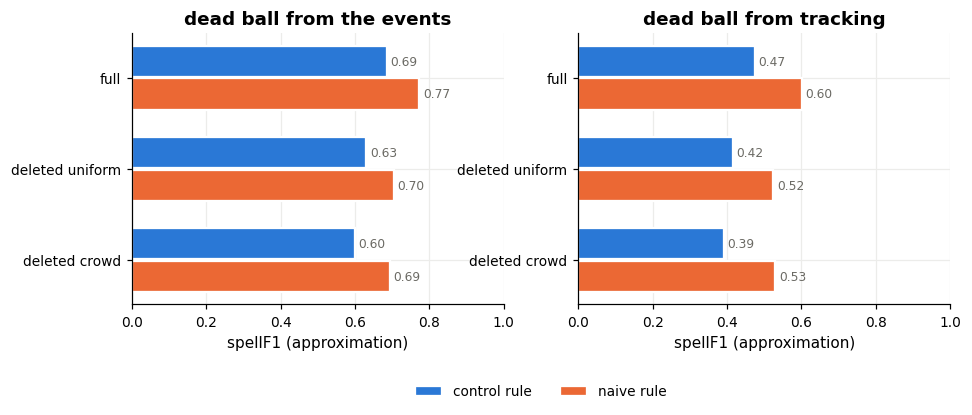

spellF1~ macroF1 possessions (true) turnover precision turnover recall turnovers within 3 frames
condition       dead ball rule                                                                                                    
full            event     control    0.685   0.922          227 (365)                84%             45%                       110
                          naive      0.772   0.927          268 (365)                82%             56%                       140
                tracking  control    0.475   0.579          190 (365)                72%             46%                       111
                          naive      0.601   0.582          260 (365)                65%             58%                       142
deleted_uniform event     control    0.630   0.883          206 (365)                81%             38%                        93
                          naive      0.704   0.885          239 (365)                81%             47%                       119
                tracking  control    0.416   0.532          170 (365)                68%             39%                        94
                          naive      0.525   0.536          228 (365)                63%             48%                       121
deleted_crowd   event     control    0.600   0.879          207 (365)                79%             37%                        88
                          naive      0.694   0.886          245 (365)                77%             47%                       114
                tracking  control    0.391   0.531          170 (365)                67%             38%                        89
                          naive      0.530   0.534          234 (365)                60%             48%                       116

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2), sharex=True)
for ax, dead, title in ((axes[0], "event_dead", "dead ball from the events"),
                        (axes[1], "tracking_dead", "dead ball from tracking")):
    for i, (cond, _) in enumerate(CONDS):
        for j, (rule, col) in enumerate((("control", BLUE), ("naive", ORANGE))):
            v = g(val, "possession", "{}:{}:{}".format(cond, dead, rule), "", "spellF1_approx")
            y = i + (j - 0.5) * 0.36
            ax.barh(y, v, height=0.34, color=col, edgecolor="white", lw=1.5,
                    label=rule + " rule" if i == 0 else None)
            ax.text(v + 0.01, y, "{:.2f}".format(v), va="center", fontsize=8, color=ph.INK_2)
    ax.set_yticks(range(len(CONDS)), [c.replace("_", " ") for c, _ in CONDS])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("spellF1 (approximation)")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.1, -0.25), ncol=2)
plt.show()

rows = []
for cond, _ in CONDS:
    for dead in ("event_dead", "tracking_dead"):
        for rule in ("control", "naive"):
            s = "{}:{}:{}".format(cond, dead, rule)
            rows.append({"condition": cond, "dead ball": dead.split("_")[0], "rule": rule,
                         "spellF1~": num(g(val, "possession", s, "", "spellF1_approx"), "{:.3f}"),
                         "macroF1": num(g(val, "possession", s, "", "macroF1"), "{:.3f}"),
                         "possessions (true)": "{:.0f} ({:.0f})".format(
                             g(val, "possession", s, "", "n_pred"), g(val, "possession", s, "", "n_true")),
                         "turnover precision": pct(g(val, "turnovers", s, "", "precision")),
                         "turnover recall": pct(g(val, "turnovers", s, "", "recall")),
                         "turnovers within 3 frames": "{:.0f}".format(g(val, "turnovers", s, "", "within_3_frames"))})
display(pd.DataFrame(rows).set_index(["condition", "dead ball", "rule"]))

**How to read this.** Bars are the approximate spellF1 of each rule (blue control, orange
naive), per ball condition. The table adds macroF1, possession counts against the event truth,
and turnover matching (±1 s, same new team).

**Takeaway.** Here the naive rule scores higher, and the reason matters more than the score.
The ball in this sample is rebuilt from the events, so it has no deflections at all: every
detected opponent touch is a real event. And the event convention calls a recovery a possession
even when the ball is lost straight away. The turnovers the control rule misses are exactly
those: their possessions last a median 3.5 s, against 8.5 s for the ones it finds. So this game
cannot settle the control-rule question; only the competition's own convention can (the public
window, read as a convention check). Two things it does settle: dead ball is worth about
0.2 spellF1 on its own (event D against tracking D, same touches); and when the control rule
switches, with dead ball from the events, it is right about 80% of the time, mostly within
3 frames.

## 3. The competition match: from peaks to touches

In [7]:
# (same run as section 1)

,count
step,
velocity-change peaks ≥ 1 m/s (visible ball),"2,492"
"of which touches, ≥ 3 m/s","1,804"
attributed to a team (≤ 2 m),"1,300"
contested,82
no player within 2 m,504
"fast ball, bending < 45° (likely lofted)",142
touches inside short gaps (bridged),20
attributed,15
live touches used by the control rule,"1,313"


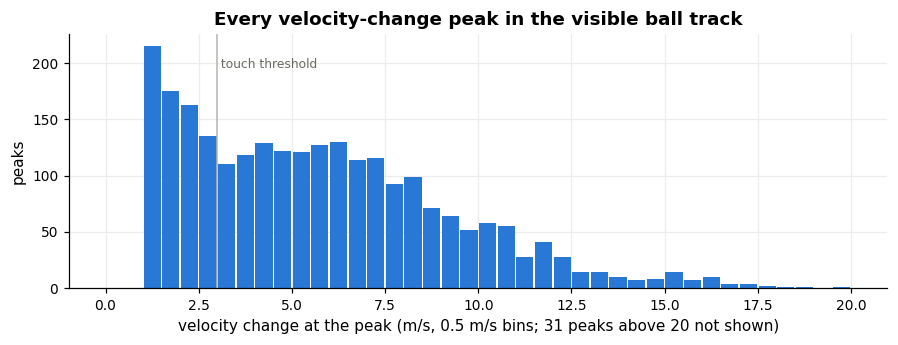

In [8]:
F = lambda scope, metric: g(tp, "funnel", scope, "", metric)
funnel = [
    ("velocity-change peaks ≥ 1 m/s (visible ball)", F("all", "peaks_over_floor")),
    ("  of which touches, ≥ 3 m/s", F("all", "visible_touches")),
    ("    attributed to a team (≤ 2 m)", F("visible", "attributed")),
    ("      contested", F("visible", "contested")),
    ("    no player within 2 m", F("visible", "no_player")),
    ("      fast ball, bending < 45° (likely lofted)", F("visible", "no_player_fast_bend")),
    ("touches inside short gaps (bridged)", F("all", "gap_touches")),
    ("  attributed", F("gap", "attributed")),
    ("live touches used by the control rule", F("all", "touches_live")),
    ("  dribbles (inside a carry)", F("all", "dribbles")),
    ("tracker glitch frames dropped", F("all", "glitch_frames_dropped")),
    ("short gaps (≤ 0.5 s) / long gaps", "{:.0f} / {:.0f}".format(F("all", "short_gaps"),
                                                             g(tp, "gaps", "long", "", "n"))),
]
display(pd.DataFrame([(a, b if isinstance(b, str) else "{:,.0f}".format(b)) for a, b in funnel],
                     columns=["step", "count"]).set_index("step"))

h = ph.pick(tp, "dv_hist", "visible_peaks", None, "count")
lo = h["bin"].str.extract(r"\[([\d.]+),")[0].astype(float).values
cnt = h["value"].values
keep = lo < 20
fig, ax = plt.subplots(figsize=(9.6, 3.0))
ax.bar(lo[keep] + 0.25, cnt[keep], width=0.46, color=BLUE)
ax.axvline(g(tp, "params", "all", "", "min_dv_ms"), color=ph.INK_3, lw=1)
ax.text(g(tp, "params", "all", "", "min_dv_ms"), cnt.max() * 0.95, " touch threshold", fontsize=8,
        color=ph.INK_2, va="top")
ax.set_xlabel("velocity change at the peak (m/s, 0.5 m/s bins; {:.0f} peaks above 20 not shown)".format(
    cnt[~keep].sum()))
ax.set_ylabel("peaks")
ax.set_title("Every velocity-change peak in the visible ball track")
plt.show()

**How to read this.** The table follows the touches step by step; the histogram shows every
peak of the velocity-change signal (w = 12) on the visible ball, with the 3 m/s threshold.

**Takeaway.** The histogram falls from the 1 m/s floor to a shallow trough near 3 m/s, then
has a broad shoulder from about 4 to 8 m/s: a noise component under a touch component. The
3 m/s threshold sits near the trough, but there is no clean gap, so it is a dial rather than a
boundary; the summary keeps the counts at 2, 3, 4 and 6 m/s (`sweep` rows). A large share of touches has no player within
2 m. About a quarter of those look like a fast ball bending in flight, which is the projection
artefact the plan expected from lofted balls.

## 4. M1: how far is the nearest player at a touch?

If real touches sit under 1.5 m and noise further out, the distance histogram has two clusters,
and the dip between them sets the attribution limit without touching the ground truth. The
reference is the same closest-approach distance at 5,000 random ball-visible frames.

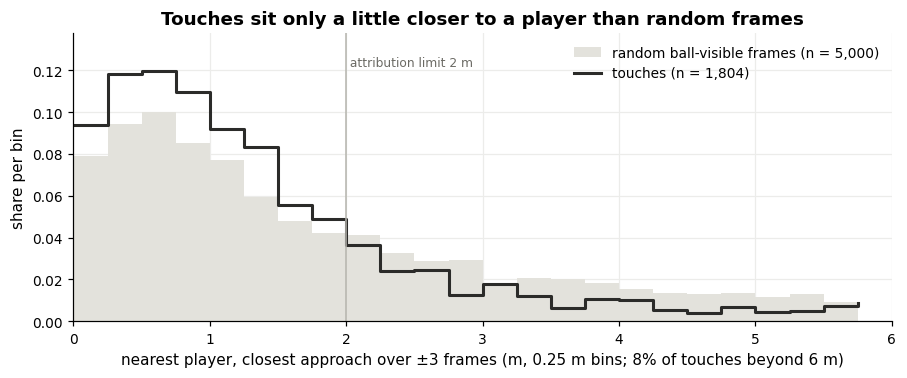

,touches,random frames
p25 (m),0.57,0.70
median (m),1.15,1.52
p75 (m),2.19,3.43
within 1 m,44%,36%
within 1.5 m,62%,50%
within 2 m,72%,59%
within 3 m,82%,72%


dip finder: mode 0.62 m, dip 1.62 m, two clusters: False


,3-5,5-10,10+
by velocity change (m/s),,,
touches,479,987,338
median distance (m),1.15,1.04,1.61
within 2 m,66%,79%,61%


In [9]:
m = ph.pick(tp, "m1_distance", None, None, "count")
lo = m[m.scope == "touches"]["bin"].str.extract(r"\[([\d.]+),")[0].astype(float).values
t = m[m.scope == "touches"]["value"].values.astype(float)
r = m[m.scope == "random_frames"]["value"].values.astype(float)
ts, rs = t / t.sum(), r / r.sum()
show = lo < 6
fig, ax = plt.subplots(figsize=(9.6, 3.4))
ax.fill_between(lo[show], 0, rs[show], step="post", color=ph.NULL_FILL, lw=0,
                label="random ball-visible frames (n = {:,.0f})".format(r.sum()))
ax.step(lo[show], ts[show], where="post", color=ph.REAL, lw=2,
        label="touches (n = {:,.0f})".format(t.sum()))
lim = g(tp, "params", "all", "", "max_dist_m")
ax.axvline(lim, color=ph.INK_3, lw=1)
ax.text(lim, ts.max() * 1.02, " attribution limit {:g} m".format(lim), fontsize=8, color=ph.INK_2)
ax.set_xlim(0, 6)
ax.set_ylim(0, max(ts.max(), rs.max()) * 1.15)
ax.set_xlabel("nearest player, closest approach over ±3 frames (m, 0.25 m bins; {:.0%} of touches beyond 6 m)"
              .format(ts[~show].sum()))
ax.set_ylabel("share per bin")
ax.set_title("Touches sit only a little closer to a player than random frames")
ax.legend(loc="upper right")
plt.show()

q = lambda scope, k: g(tp, "m1_distance", scope, "", k)
display(pd.DataFrame({
    scope.replace("_", " "): {"p25 (m)": num(q(scope, "p25")), "median (m)": num(q(scope, "p50")),
                              "p75 (m)": num(q(scope, "p75")),
                              "within 1 m": pct(q(scope, "share_within_1m")),
                              "within 1.5 m": pct(q(scope, "share_within_1.5m")),
                              "within 2 m": pct(q(scope, "share_within_2m")),
                              "within 3 m": pct(q(scope, "share_within_3m"))}
    for scope in ("touches", "random_frames")}))
print("dip finder: mode {:.2f} m, dip {} m, two clusters: {}".format(
    q("touches", "mode1"), num(q("touches", "dip")), bool(q("touches", "bimodal"))))
display(pd.DataFrame({b: {"touches": "{:.0f}".format(g(tp, "m1_by_dv", "touches", b, "n")),
                          "median distance (m)": num(g(tp, "m1_by_dv", "touches", b, "median")),
                          "within 2 m": pct(g(tp, "m1_by_dv", "touches", b, "share_within_2m"))}
                      for b in ("3-5", "5-10", "10+")}).rename_axis("by velocity change (m/s)"))

**How to read this.** The dark line is the share of touches per 0.25 m distance bin; the grey
area is the same for random frames where the ball is visible. Two clusters would show up as a
second hump in the dark line, far from the first.

**Takeaway.** There is one cluster, not two, and it is only modestly closer than random frames
(median about 1.15 m against 1.5 m). The plan's data-driven limit therefore does not exist on
this track: the dip finder reports no two clusters. Two reasons fit the other sections. The
ball is smoothed (section 1), so at a touch it is averaged with where it was and where it went.
And on random visible frames the ball is usually at someone's feet anyway, because it goes
missing in the air and in crowds. The strongest velocity changes (≥ 10 m/s) are the *furthest*
from a player: shots, clearances and lofted balls, whose ground projection is off. The 2 m limit
stays a judgement call; a softer attribution (a weight that falls with distance, fed to the HMM)
fits this better than a hard cut.

## 5. M2: how much work does the control rule have to do?

Among consecutive uncontested touches (no half start, dead ball or long gap between them): how
often does the team change, and how often does that change undo itself straight away, after one
touch or within 2 s?

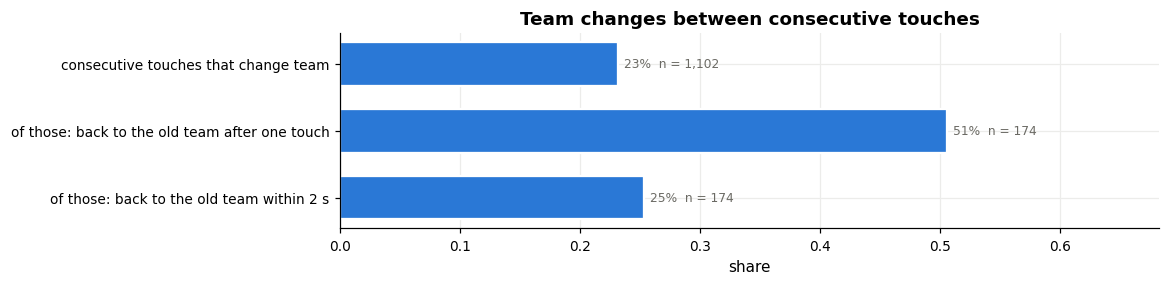

In [10]:
M = lambda k: g(tp, "m2_consecutive", "all", "", k)
labels = ["consecutive touches that change team",
          "of those: back to the old team after one touch",
          "of those: back to the old team within 2 s"]
vals = [M("switch_share"), M("back_after_1_touch_share"), M("back_within_s_share")]
ns = [M("n_pairs"), M("n_back_evaluable"), M("n_back_evaluable")]
fig, ax = plt.subplots(figsize=(9.6, 2.3))
ph.bars_with_n(ax, labels, vals, ns, colours=BLUE, horizontal=True, fmt="{:.0%}")
ax.set_xlabel("share")
ax.set_title("Team changes between consecutive touches")
plt.show()

**How to read this.** The first bar is the share of consecutive touch pairs whose teams differ.
The other two take those changes that can be followed up, meaning another touch comes before a
break, and give the share that return to the old team at once or within 2 s.

**Takeaway.** About a quarter of consecutive touches change team, and half of those changes
undo themselves after a single touch. Under the naive rule each of those is two extra
possessions. This is the H | A | H pattern the control rule exists for, and it is common:
deflections, blocks, and touches given to the wrong player because the ball is smoothed. The
control rule turns 292 naive turnovers into 135.

## 6. M3: how many switches happen where the ball is missing?

For each control-rule turnover, the interval from the old team's last touch to the new team's
first touch: does it contain a ball gap? The same for raw team changes between consecutive
touches (broken only by dead ball here). A switch inside a long gap is invisible to touches:
that share is the ceiling of a touch-only approach.

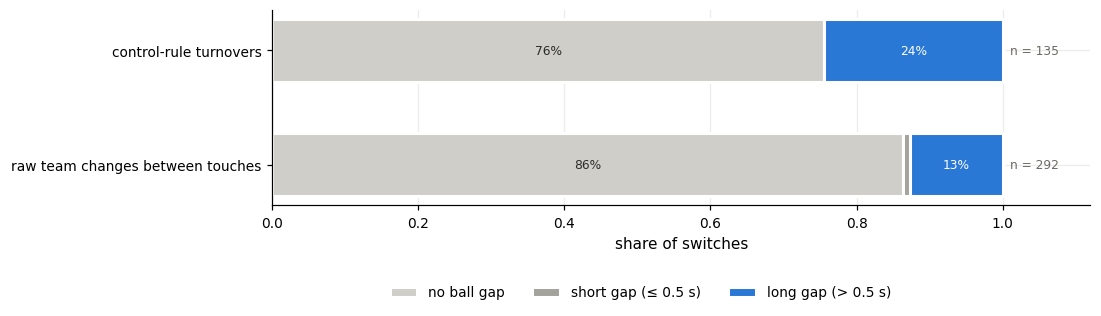

,control-rule turnovers,raw team changes between touches
no ball gap,102,252
short gap (≤ 0.5 s),0,3
long gap (> 0.5 s),33,37
longest gap ≥ 5 s,33,37


long ball gaps: 141; same team in control on both sides 70, a turnover hidden inside 48, next to dead ball or a half edge 23


In [11]:
CLS = [("no_gap", "no ball gap", ph.GREYS[3]), ("short_gap", "short gap (≤ 0.5 s)", ph.GREYS[2]),
       ("long_gap", "long gap (> 0.5 s)", BLUE)]
ROWS = [("control", "control-rule turnovers"), ("raw", "raw team changes between touches")]
fig, ax = plt.subplots(figsize=(9.6, 2.3))
for i, (scope, name) in enumerate(ROWS):
    n = g(tp, "m3_gap_span", scope, "", "n_switches")
    left = 0.0
    for key, lab, col in CLS:
        s = g(tp, "m3_gap_span", scope, key, "share")
        ax.barh(i, s, left=left, height=0.55, color=col, edgecolor="white", lw=2,
                label=lab if i == 0 else None)
        if s >= 0.08:
            ax.text(left + s / 2, i, "{:.0%}".format(s), ha="center", va="center", fontsize=8,
                    color="white" if col == BLUE else ph.REAL)
        left += s
    ax.text(1.01, i, "n = {:.0f}".format(n), va="center", fontsize=8, color=ph.INK_2)
ax.set_yticks(range(len(ROWS)), [n for _, n in ROWS])
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xlabel("share of switches")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.35), ncol=3)
plt.show()

display(pd.DataFrame({name: {lab: "{:.0f}".format(g(tp, "m3_gap_span", scope, key, "count"))
                             for key, lab, _ in CLS} |
                      {"longest gap ≥ 5 s": "{:.0f}".format(g(tp, "m3_gap_span", scope, "longest:>=5s", "count"))}
                      for scope, name in ROWS}))
G = lambda k: g(tp, "gaps", "long", k, "count")
print("long ball gaps: {:.0f}; same team in control on both sides {:.0f}, a turnover hidden inside {:.0f}, "
      "next to dead ball or a half edge {:.0f}".format(g(tp, "gaps", "long", "", "n"), G("same"),
                                                       G("differs"), G("unknown")))

**How to read this.** Each bar splits the switches by the longest ball gap between the old
team's last touch and the new team's first. Blue is the part a touch detector cannot place,
because the change happened while the ball was missing. Every one of those gaps lasts 5 s or
more.

**Takeaway.** About a quarter of the control-rule turnovers (and an eighth of raw team changes)
hide inside a long ball gap. Of the long gaps that can be judged, about 40% contain a change of
team, which matches `ball_gaps.py`'s flip rate across gaps (0.41). The ball is missing on 41% of
graded frames, almost all of it in gaps of 5 s or more, so the gap handling and the ball-free
features (team shape, territory, the HMM) set the ceiling more than touch detection does. Short
gaps hardly matter on this match: there are only about 20.

## 7. M4: do switches line up with Smart Tagging's transitions?

Smart Tagging tags 24 transitions. Each is tagged twice at the same start, as ATTACKING
TRANSITION for the team that won the ball and DEFENSIVE TRANSITION for the team that lost it,
so the numbers below count each once. For each rule: the share of our turnovers with a
transition start within W, the share of transitions with a turnover within W, both against the
same tags shifted circularly within each half (1000 shifts, at least 60 s; the `tag_gaps.py`
null), and whether the tag's team is the switch's new team.

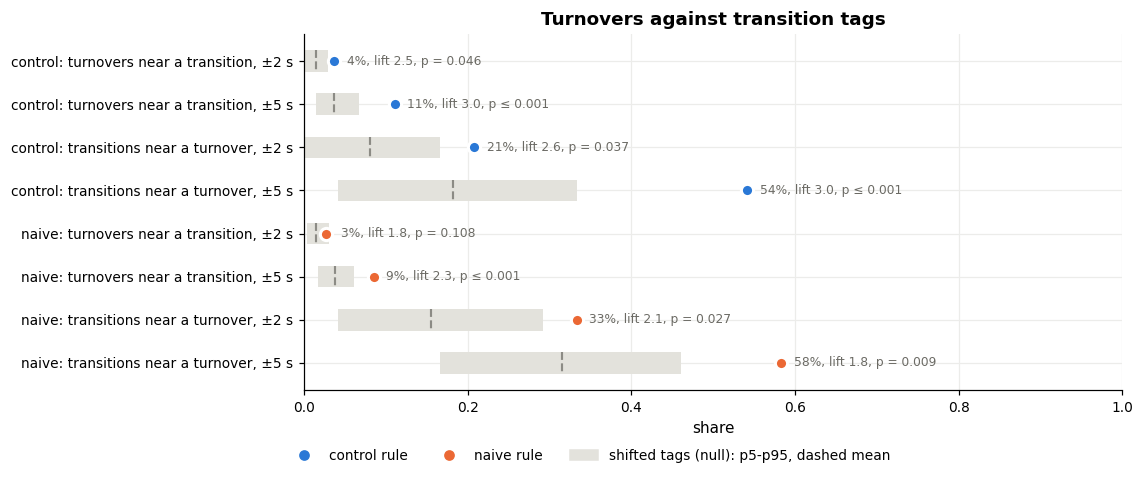

,control,naive
turnovers,135,292
transitions,24,24
near a tag ±5 s (null),11% (4%),9% (4%)
tags matched ±5 s (null),54% (18%),58% (32%)
team agrees ±5 s,8 of 13,6 of 14
"offset median, switch - tag (s)",0.72,-0.52


In [12]:
K = int(g(tp, "params", "all", "", "null_n"))
GRP = "ATTACKING TRANSITION"
items = []
for rule, col in (("control", BLUE), ("naive", ORANGE)):
    for metric, lab in (("precision", "turnovers near a transition"),
                        ("recall", "transitions near a turnover")):
        for w in (2, 5):
            items.append((rule, col, metric, lab, w))
fig, ax = plt.subplots(figsize=(9.6, 4.2))
for i, (rule, col, metric, lab, w) in enumerate(items):
    s = "{}:{}".format(rule, GRP)
    b = "w{}s".format(w)
    real = g(tp, "m4_tags", s, b, metric)
    ph.null_interval(ax, i, g(tp, "m4_tags", s, b, metric + "_null_p5"),
                     g(tp, "m4_tags", s, b, metric + "_null_p95"),
                     g(tp, "m4_tags", s, b, metric + "_null_mean"))
    ax.plot(real, i, "o", ms=8, color=col, mec="white", mew=2)
    ax.text(max(real, g(tp, "m4_tags", s, b, metric + "_null_p95")) + 0.015, i,
            "{:.0%}, lift {:.1f}, {}".format(real, g(tp, "m4_tags", s, b, metric + "_lift"),
                                              ph.fmt_p(g(tp, "m4_tags", s, b, metric + "_p_emp"), K)),
            va="center", fontsize=8, color=ph.INK_2)
ax.set_yticks(range(len(items)), ["{}: {}, ±{} s".format(r, l, w) for r, _, _, l, w in items])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share")
ax.plot([], [], "o", color=BLUE, label="control rule")
ax.plot([], [], "o", color=ORANGE, label="naive rule")
ax.fill_between([], [], [], color=ph.NULL_FILL, label="shifted tags (null): p5-p95, dashed mean")
ax.legend(loc="upper center", bbox_to_anchor=(0.35, -0.13), ncol=3)
ax.set_title("Turnovers against transition tags")
plt.show()

rows = {}
for rule in ("control", "naive"):
    s = "{}:{}".format(rule, GRP)
    rows[rule] = {"turnovers": "{:.0f}".format(g(tp, "m4_tags", rule, "", "n_switches")),
                  "transitions": "{:.0f}".format(g(tp, "m4_tags", s, "", "n_anchors")),
                  "near a tag ±5 s (null)": "{} ({})".format(pct(g(tp, "m4_tags", s, "w5s", "precision")),
                                                         pct(g(tp, "m4_tags", s, "w5s", "precision_null_mean"))),
                  "tags matched ±5 s (null)": "{} ({})".format(pct(g(tp, "m4_tags", s, "w5s", "recall")),
                                                           pct(g(tp, "m4_tags", s, "w5s", "recall_null_mean"))),
                  "team agrees ±5 s": "{:.0f} of {:.0f}".format(
                      g(tp, "m4_tags", s, "w5s", "team_agree"),
                      g(tp, "m4_tags", s, "w5s", "team_agree") + g(tp, "m4_tags", s, "w5s", "team_disagree")),
                  "offset median, switch - tag (s)": num(g(tp, "m4_offsets", s, "", "p50"))}
display(pd.DataFrame(rows))

**How to read this.** Each row is one share: a dot for the real tags, a grey band for the
shifted tags (p5-p95, dashed mean). A dot right of its band beats chance; the label gives the
real share, lift over the null mean and the empirical p.

**Takeaway.** Both rules beat chance, and the control rule beats it by more. Its turnovers sit
near a transition about 3 times as often as near shifted tags (p ≤ 0.001), against 2.3 times
for the naive rule. When a transition does have a turnover nearby, the control rule usually
gives the ball to the team Smart Tagging names (8 of 13); the naive rule gets it right 6 of
14 times, a coin flip. Precision stays low in absolute terms (about 11%), because Smart Tagging
tags only 24 transitions in the match while there are hundreds of turnovers. These are small
counts, so they show direction, not size.

## 8. What does that make of the possessions?

The labels after the scorer's fill: possession counts, lengths and label shares. The reference
lines are the published numbers of the public 5-minute window (DATA.md: 17 possessions, H 3,454,
A 2,577, D 1,469 of 7,500 frames). They are context for the order of magnitude only: one
window, five minutes, not a target.

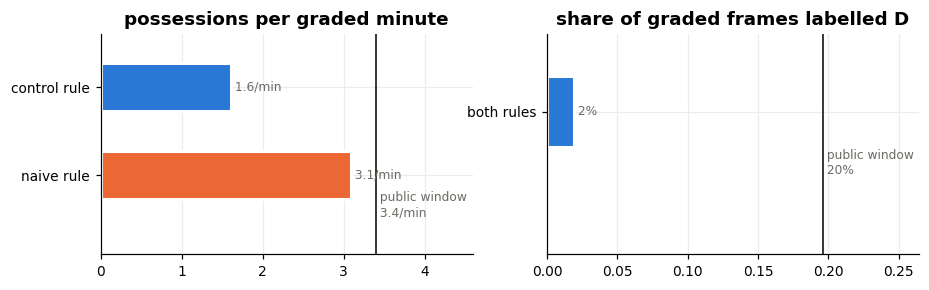

,control,naive
possessions,170,327
per graded minute,1.61,3.09
mean / median length (s),34.3 / 20.3,17.8 / 8.6
under 2 s,4%,17%
turnovers (two touches / carry / receive),135 (69 / 47 / 19),292 (0 / 0 / 0)
restarts,35,35
labels H / A / D / X,43% / 31% / 2% / 25%,40% / 32% / 2% / 26%


control rule: median delay from the switch frame to the touch that confirmed it 0.68 s (p90 3.5 s)


In [13]:
P = lambda rule, k: g(tp, "possessions", rule, "", k)
L = lambda rule, ch: g(tp, "labels", rule, ch, "share_graded")
REF_RATE, REF_D = 17 / 5.0, 1469 / 7500.0
fig, axes = plt.subplots(1, 2, figsize=(9.6, 2.6), gridspec_kw={"width_ratios": [1, 1]})
for ax, vals, names, cols, ref, fmt, title in (
        (axes[0], [P("control", "per_min"), P("naive", "per_min")], ["control rule", "naive rule"],
         [BLUE, ORANGE], REF_RATE, "{:.1f}/min", "possessions per graded minute"),
        (axes[1], [L("control", "D")], ["both rules"], [BLUE], REF_D, "{:.0%}",
         "share of graded frames labelled D")):
    ys = np.arange(len(vals))
    ax.barh(ys, vals, height=0.55, color=cols, edgecolor="white", lw=2)
    for i, v in enumerate(vals):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=8, color=ph.INK_2)
    ax.axvline(ref, color=ph.REAL, lw=1.2)
    ax.text(ref, len(vals) - 0.5, " public window\n " + fmt.format(ref), fontsize=8,
            color=ph.INK_2, va="bottom")
    ax.set_yticks(ys, names)
    ax.set_ylim(len(vals) - 0.5 + (0.6 if len(vals) == 1 else 0.4), -0.6)
    ax.set_xlim(0, max(max(vals), ref) * 1.35)
    ax.set_title(title)
plt.show()

display(pd.DataFrame({rule: {
    "possessions": "{:.0f}".format(P(rule, "n")),
    "per graded minute": num(P(rule, "per_min"), "{:.2f}"),
    "mean / median length (s)": "{:.1f} / {:.1f}".format(P(rule, "mean_s"), P(rule, "median_s")),
    "under 2 s": pct(P(rule, "share_under_2s")),
    "turnovers (two touches / carry / receive)": "{:.0f} ({:.0f} / {:.0f} / {:.0f})".format(
        g(tp, "switches", rule, "", "turnovers"), g(tp, "switches", rule, "two_touches", "turnovers"),
        g(tp, "switches", rule, "carry", "turnovers"), g(tp, "switches", rule, "receive", "turnovers")),
    "restarts": "{:.0f}".format(g(tp, "switches", rule, "", "restarts")),
    "labels H / A / D / X": " / ".join(pct(L(rule, ch)) for ch in "HADX")}
    for rule in ("control", "naive")}))
print("control rule: median delay from the switch frame to the touch that confirmed it {:.2f} s (p90 {:.1f} s)"
      .format(g(tp, "switches", "control", "", "confirm_delay_p50"),
              g(tp, "switches", "control", "", "confirm_delay_p90")))

**How to read this.** Left: possessions per graded minute for each rule, against the public
window's rate. Right: the share of graded frames labelled D, against the public window's share.
The table has the counts behind them.

**Takeaway.** The control rule produces about half the naive rule's possessions, and both sit
below the public window's rate. The right panel says why: our dead-ball signals cover about 2% of
graded frames where the public window has about 20%. A missed stoppage can merge the
possessions on either side of it. The X share (about a quarter) is the long ball gaps with the
same team on both sides, which the scorer fills with the previous label. So the next gain is not in the touch logic. It is in
recognising dead ball while the ball is missing, which is most of the time it is dead.

## 9. Summary and next steps

- **Detection works, at the provider's time scale.** The ATD ball is smoothed over about 0.5 s,
  so touches are found with w = 12, not 3-5 frames. On clean open data, the same detector finds
  about 90% of visible touches at 98% precision and gives them to the right team.
- **There are no distance clusters on this track.** Touches are only modestly closer to a
  player than random frames, so a hard 2 m limit is a judgement call. A distance-weighted touch
  likelihood suits the HMM better.
- **The control rule is needed.** A quarter of consecutive touches change team and half of those
  undo themselves at once; the rule halves the turnovers, and the ones it keeps line up better
  with Smart Tagging's transitions, on both timing and team.
- **The ceiling is the ball gaps and dead ball, not the touches.** A quarter of turnovers happen
  inside long gaps, and dead ball is about 2% of frames where it should be about 20%.

Next steps:
1. Feed the touches to the HMM as evidence at touch frames, with confidence from the
   distance, the contested flag and the velocity change, rather than as hard switches.
2. Recognise dead ball inside long gaps: players slowing down, restart shapes and the next
   still-ball restart, with Smart Tagging's set pieces as weak evidence.
3. Place switches inside the 48 long gaps that hide one, using the ball-free features.
4. Run `--gt` on the public window once, to see whether its switches sit at the new team's first
   touch, and whether the smoothed track's touch frames lead or lag them. Read it, don't tune on it.